### Calculate the root of the quadratic equation without using LLM

In [4]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict,Literal

In [5]:
# define state for quadratic Equation
class QuadraticState(TypedDict):
    a: float
    b: float
    c: float

    equation : str
    discriminant : float
    real_roots : str

In [6]:
# show Equation Node
def show_equation(state: QuadraticState):
    state['equation'] = f"{state['a']}x^2 + {state['b']}x + {state['c']} = 0"
    return {'equation': state['equation']}

# Node for calculating discriminant
def calculate_discriminant(state: QuadraticState):
    state['discriminant'] = state['b']**2 - 4*state['a']*state['c']
    return {'discriminant': state['discriminant']}  

# Node for calculating real roots
def calculate_real_roots(state: QuadraticState):    
    if state['discriminant'] < 0:
        state['real_roots'] = "No real roots"
    elif state['discriminant'] == 0:
        root = -state['b'] / (2 * state['a'])
        state['real_roots'] = f"One real root: {root}"
    else:
        root1 = (-state['b'] + state['discriminant']**0.5) / (2 * state['a'])
        root2 = (-state['b'] - state['discriminant']**0.5) / (2 * state['a'])
        state['real_roots'] = f"Two real roots: {root1} and {root2}"
    return {'real_roots': state['real_roots']}

# Node for repeated root
def calculate_repeated_root(state: QuadraticState):
    if state['discriminant'] == 0:
        root = -state['b'] / (2 * state['a'])
        state['real_roots'] = f"Repeated root: {root}"
    return {'real_roots': state['real_roots']}

# Node for no real roots
def no_real_roots(state: QuadraticState):
    if state['discriminant'] < 0:
        state['real_roots'] = "No real roots"
    return {'real_roots': state['real_roots']}

# Node for check condition of discriminant
def check_discriminant(state: QuadraticState):
    if state['discriminant'] < 0:
        return {'condition': 'no_real_roots'}
    elif state['discriminant'] == 0:
        return {'condition': 'repeated_root'}
    else:
        return {'condition': 'two_real_roots'} 

In [23]:
graph = StateGraph(QuadraticState)

graph.add_node("show_equation", show_equation)
graph.add_node("calculate_discriminant", calculate_discriminant)
graph.add_node("check_discriminant", check_discriminant)
graph.add_node("calculate_real_roots", calculate_real_roots)
graph.add_node("calculate_repeated_root", calculate_repeated_root)
graph.add_node("no_real_roots", no_real_roots)

graph.add_edge(START, "show_equation")
graph.add_edge("show_equation", "calculate_discriminant")
graph.add_edge("calculate_discriminant", "check_discriminant")

graph.add_conditional_edges(
    "check_discriminant",
    lambda state: state["condition"],
    {
        "two_real_roots": "calculate_real_roots",
        "repeated_root": "calculate_repeated_root",
        "no_real_roots": "no_real_roots",
    },
)

graph.add_edge("calculate_real_roots", END)
graph.add_edge("calculate_repeated_root", END)
graph.add_edge("no_real_roots", END)

workflow = graph.compile()

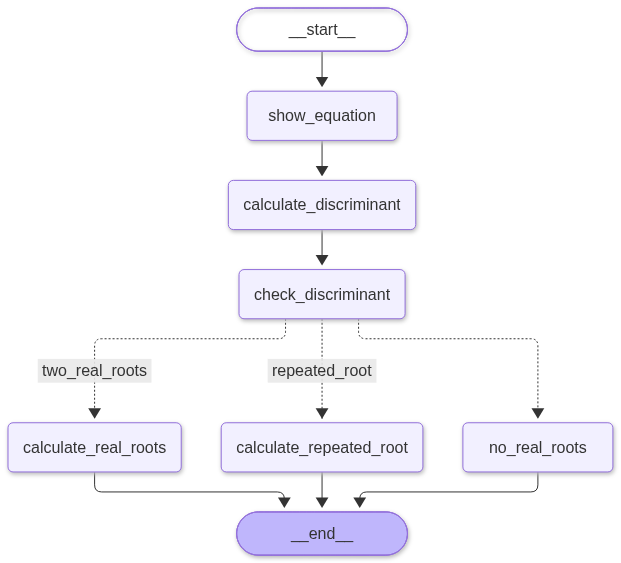

In [24]:
workflow

In [25]:
# check the workflow with sample input
input_data = {"a": 1, "b": -5, "c": 6}
output = workflow.invoke(input_data)
print(output)

{'a': 1, 'b': -5, 'c': 6, 'equation': '1x^2 + -5x + 6 = 0', 'discriminant': 1, 'real_roots': 'Two real roots: 3.0 and 2.0'}
